# 01 – Data analysis of MovieLens 1M

## 0. Setup

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

# Some hacks to be able to import properly
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.model import Dataset
from src.data.splitting import split

with open(ROOT / "config.yaml") as f:
    cfg = yaml.safe_load(f)

DATA_DIR = Path(os.environ.get("DATA_DIR", ROOT / "data" / "ml-1m"))

pd.set_option("display.float_format", "{:,.4f}".format)
plt.rcParams["figure.dpi"] = 100

SUMMARY = []  # (section, metric, value) rows collected for the final table

def record(section, metric, value):
    SUMMARY.append((section, metric, value))
    return value

In [2]:
ds = Dataset.from_config(str(DATA_DIR), cfg["load"])
movies, users = ds.movies, ds.users
ratings = ds.ratings.copy()  # copy so the extra "date" column does not leak into ds
ratings["date"] = pd.to_datetime(ratings["ts"], unit="s")
ratings.head()

,user_id,item_id,rating,ts,date
0,1,1193,5,978300760,2000-12-31 22:12:40
1,1,661,3,978302109,2000-12-31 22:35:09
2,1,914,3,978301968,2000-12-31 22:32:48
3,1,3408,4,978300275,2000-12-31 22:04:35
4,1,2355,5,978824291,2001-01-06 23:38:11


## 1. Basic statistics

Size of the user–item matrix and its density and per-user rating count,

In [3]:
n_users, n_items, n_ratings = ds.n_users, ds.n_items, ds.n_ratings
n_movies_file = movies["item_id"].nunique()
n_never_rated = len(set(movies["item_id"]) - set(ratings["item_id"]))
n_users_file = users["user_id"].nunique()
density = n_ratings / (n_users * n_items)

per_user = ratings.groupby("user_id").size()
per_item = ratings.groupby("item_id").size()

basic = pd.Series({
    "users (with >= 1 rating)": n_users,
    "users in users.dat": n_users_file,
    "movies (with >= 1 rating)": n_items,
    "movies in movies.dat": n_movies_file,
    "movies never rated": n_never_rated,
    "ratings": n_ratings,
    "density": density,
    "duplicate ratings": int(ratings.duplicated(["user_id", "item_id"]).sum()),
}, dtype=object)
display(basic.to_frame("value"))

activity = pd.DataFrame({
    "ratings per user": per_user.describe(percentiles=[.25, .5, .75, .9, .99]),
    "ratings per item": per_item.describe(percentiles=[.25, .5, .75, .9, .99]),
})
display(activity)

for k, v in [("users", n_users), ("items rated", n_items), ("movies in movies.dat", n_movies_file),
             ("movies never rated", n_never_rated), ("ratings", n_ratings), ("density", round(density, 4)),
             ("min / median / max ratings per user", f"{per_user.min()} / {per_user.median():.0f} / {per_user.max()}"),
             ("min / median / max ratings per item", f"{per_item.min()} / {per_item.median():.0f} / {per_item.max()}")]:
    record("1 basic", k, v)

,value
users (with >= 1 rating),6040
users in users.dat,6040
movies (with >= 1 rating),3706
movies in movies.dat,3883
movies never rated,177
ratings,1000209
density,0.0447
duplicate ratings,0


,ratings per user,ratings per item
count,"6,040.0000","3,706.0000"
mean,165.5975,269.8891
std,192.7470,384.0478
min,20.0000,1.0000
25%,44.0000,33.0000
50%,96.0000,123.5000
75%,208.0000,350.0000
90%,400.0000,729.5000
99%,906.6600,"1,784.9000"
max,"2,314.0000","3,428.0000"


## 2. Long tail

How concentrated the ratings are on popular items. This motivates reporting coverage / popularity-bias
metrics and explains why a Most-Popular baseline is strong.

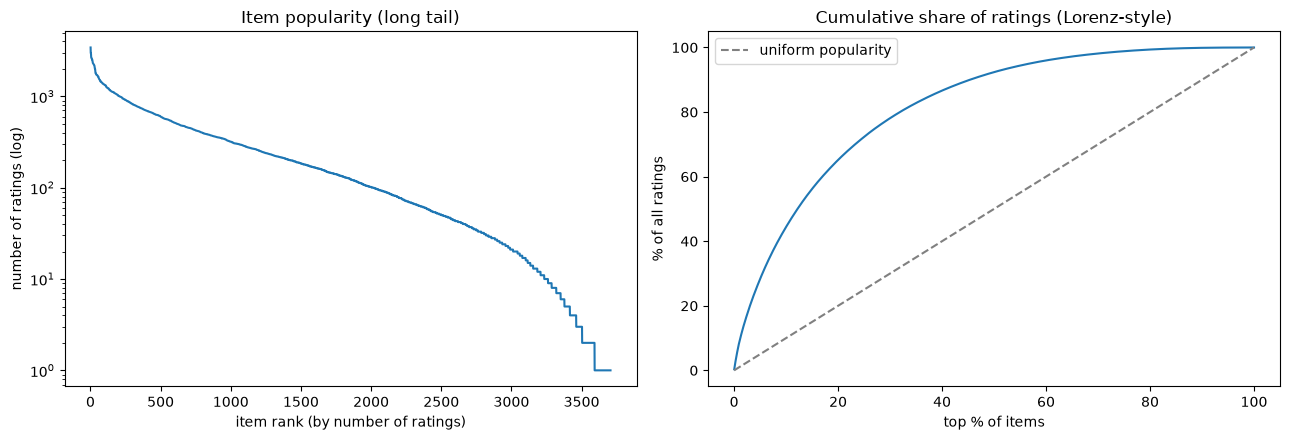

,top % of items,n items,% of ratings
0,1,37,8.7312
1,5,185,28.2754
2,10,371,44.4541
3,20,741,65.1641


Items needed for 50% of ratings: 452 (12.2% of rated items)
Gini item popularity: 0.634   Gini user activity: 0.529
Items with < 5 ratings: 290,  < 20 ratings: 663


In [4]:
def gini(x):
    """Gini coefficient of a non-negative array (0 = all equal, 1 = all mass on one element)."""
    x = np.sort(np.asarray(x, dtype=float))
    n = len(x)
    cum = np.cumsum(x)
    return (n + 1 - 2 * (cum / cum[-1]).sum()) / n

def top_share(counts, frac):
    """Share of all ratings that go to the top `frac` most-rated entities."""
    s = np.sort(np.asarray(counts))[::-1]
    k = max(1, int(round(frac * len(s))))
    return s[:k].sum() / s.sum()

pop_sorted = per_item.sort_values(ascending=False).to_numpy()
cum_share = np.cumsum(pop_sorted) / pop_sorted.sum()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(np.arange(1, len(pop_sorted) + 1), pop_sorted)
axes[0].set_yscale("log")
axes[0].set_xlabel("item rank (by number of ratings)")
axes[0].set_ylabel("number of ratings (log)")
axes[0].set_title("Item popularity (long tail)")

x_frac = np.arange(1, len(pop_sorted) + 1) / len(pop_sorted)
axes[1].plot(x_frac * 100, cum_share * 100)
axes[1].plot([0, 100], [0, 100], "--", color="grey", label="uniform popularity")
axes[1].set_xlabel("top % of items")
axes[1].set_ylabel("% of all ratings")
axes[1].set_title("Cumulative share of ratings (Lorenz-style)")
axes[1].legend()
plt.tight_layout()
plt.show()

tail = pd.DataFrame({
    "top % of items": [1, 5, 10, 20],
    "n items": [max(1, int(round(f / 100 * n_items))) for f in [1, 5, 10, 20]],
    "% of ratings": [100 * top_share(per_item, f / 100) for f in [1, 5, 10, 20]],
})
display(tail)
for _, r in tail.iterrows():
    record("2 long tail", f"% of ratings on top {int(r['top % of items'])}% items", round(r["% of ratings"], 1))
items_for_half = int(np.searchsorted(cum_share, 0.5) + 1)
record("2 long tail", "items needed for 50% of ratings", f"{items_for_half} ({100 * items_for_half / n_items:.1f}%)")
record("2 long tail", "Gini of item popularity", round(gini(per_item), 3))
record("2 long tail", "Gini of user activity", round(gini(per_user), 3))
print(f"Items needed for 50% of ratings: {items_for_half} ({100 * items_for_half / n_items:.1f}% of rated items)")
print(f"Gini item popularity: {gini(per_item):.3f}   Gini user activity: {gini(per_user):.3f}")
print(f"Items with < 5 ratings: {(per_item < 5).sum()},  < 20 ratings: {(per_item < 20).sum()}")

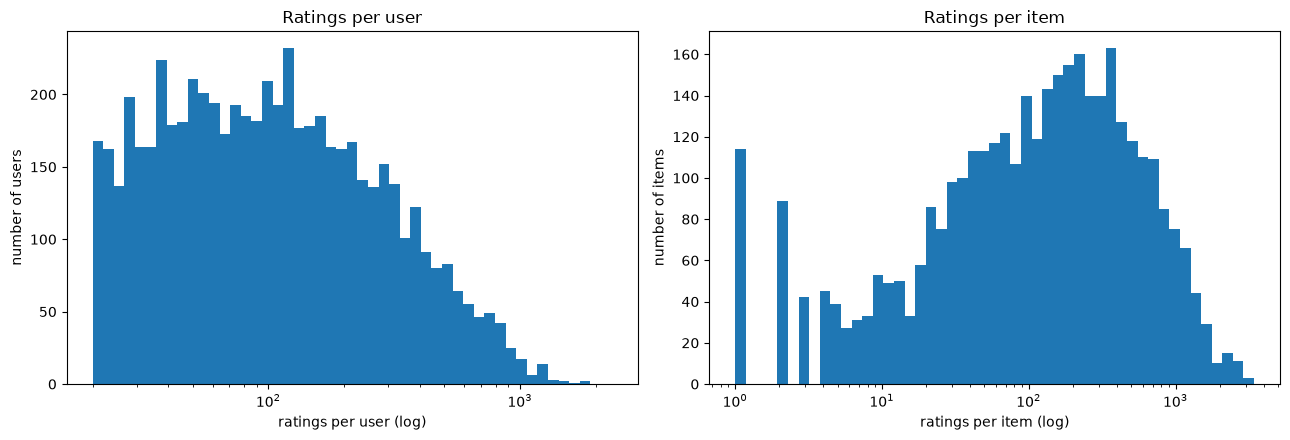

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(per_user, bins=np.logspace(np.log10(per_user.min()), np.log10(per_user.max()), 50))
axes[0].set_xscale("log")
axes[0].set_xlabel("ratings per user (log)")
axes[0].set_ylabel("number of users")
axes[0].set_title("Ratings per user")

axes[1].hist(per_item, bins=np.logspace(0, np.log10(per_item.max()), 50))
axes[1].set_xscale("log")
axes[1].set_xlabel("ratings per item (log)")
axes[1].set_ylabel("number of items")
axes[1].set_title("Ratings per item")
plt.tight_layout()
plt.show()

## 3. Rating distribution

Informs the relevance threshold for "positive" feedback (evaluation uses rating ≥ 4) – compared with per-user thresholds at the end of Section 5 and the
"count only positive ratings" variant of the Most-Popular baseline.

,count,share %
rating,,
1,56174,5.6162
2,107557,10.7535
3,261197,26.1142
4,348971,34.8898
5,226310,22.6263


mean rating: 3.582
share rating >= 4: 57.5%   share rating >= 5: 22.6%
users with no rating >= 4: 2


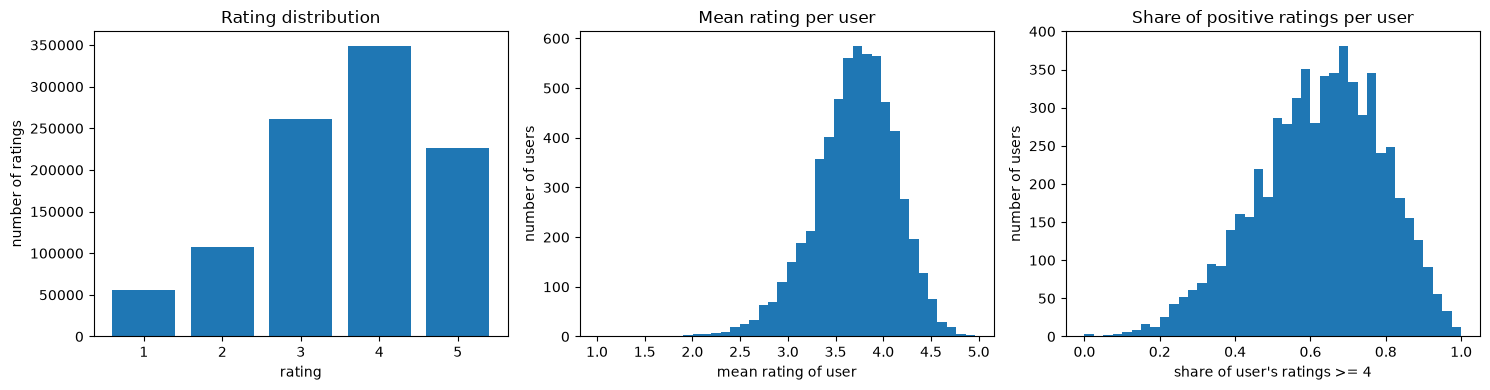

In [6]:
RELEVANCE_THRESHOLD = 4

dist = ratings["rating"].value_counts().sort_index().to_frame("count")
dist["share %"] = 100 * dist["count"] / n_ratings
display(dist)

share_ge4 = (ratings["rating"] >= 4).mean()
share_ge5 = (ratings["rating"] >= 5).mean()
print(f"mean rating: {ratings['rating'].mean():.3f}")
print(f"share rating >= 4: {100 * share_ge4:.1f}%   share rating >= 5: {100 * share_ge5:.1f}%")
record("3 ratings", "mean rating", round(ratings["rating"].mean(), 3))
record("3 ratings", "% ratings >= 4", round(100 * share_ge4, 1))
record("3 ratings", "% ratings = 5", round(100 * share_ge5, 1))

user_mean = ratings.groupby("user_id")["rating"].mean()
user_pos_share = ratings.assign(pos=ratings["rating"] >= RELEVANCE_THRESHOLD).groupby("user_id")["pos"].mean()
print(f"users with no rating >= {RELEVANCE_THRESHOLD}: {(user_pos_share == 0).sum()}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].bar(dist.index, dist["count"])
axes[0].set_xlabel("rating")
axes[0].set_ylabel("number of ratings")
axes[0].set_title("Rating distribution")
axes[1].hist(user_mean, bins=40)
axes[1].set_xlabel("mean rating of user")
axes[1].set_ylabel("number of users")
axes[1].set_title("Mean rating per user")
axes[2].hist(user_pos_share, bins=40)
axes[2].set_xlabel(f"share of user's ratings >= {RELEVANCE_THRESHOLD}")
axes[2].set_ylabel("number of users")
axes[2].set_title("Share of positive ratings per user")
plt.tight_layout()
plt.show()

## 4. Time

Timestamps are when the rating was *entered*, not when the film was watched. This section shows how
activity is spread over the time span, which matters for where a global temporal cut lands and how
many users are still active after it.

In [7]:
t_min, t_max = ratings["date"].min(), ratings["date"].max()
span_days = (t_max - t_min).days
print(f"first rating: {t_min}   last rating: {t_max}   span: {span_days} days ({span_days / 365:.2f} years)")
record("4 time", "first / last rating", f"{t_min.date()} / {t_max.date()}")
record("4 time", "span (days)", span_days)

weekly = ratings.set_index("date").resample("W").size()
monthly = ratings.set_index("date").resample("MS").size()
month_table = pd.DataFrame({"ratings": monthly, "cumulative %": 100 * monthly.cumsum() / n_ratings})

for n in [1, 3, 6, 12]:
    share = 100 * month_table["ratings"].iloc[:n].sum() / n_ratings
    print(f"share of ratings in the first {n:2d} calendar month(s): {share:.1f}%")
    record("4 time", f"% ratings in first {n} month(s)", round(share, 1))
display(month_table.head(12))

first rating: 2000-04-25 23:05:32   last rating: 2003-02-28 17:49:50   span: 1038 days (2.84 years)


share of ratings in the first  1 calendar month(s): 1.1%
share of ratings in the first  3 calendar month(s): 13.3%
share of ratings in the first  6 calendar month(s): 45.8%
share of ratings in the first 12 calendar month(s): 93.7%


,ratings,cumulative %
date,,
2000-04-01,11396,1.1394
2000-05-01,67437,7.8817
2000-06-01,54486,13.3291
2000-07-01,90334,22.3606
2000-08-01,182109,40.5677
2000-09-01,52421,45.8087
2000-10-01,42294,50.0372
2000-11-01,290793,79.1105
2000-12-01,113487,90.4568


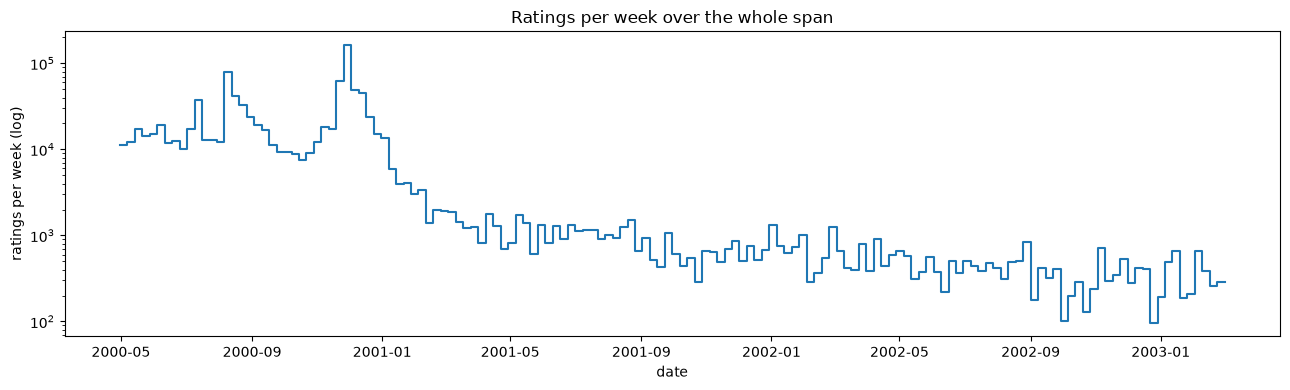

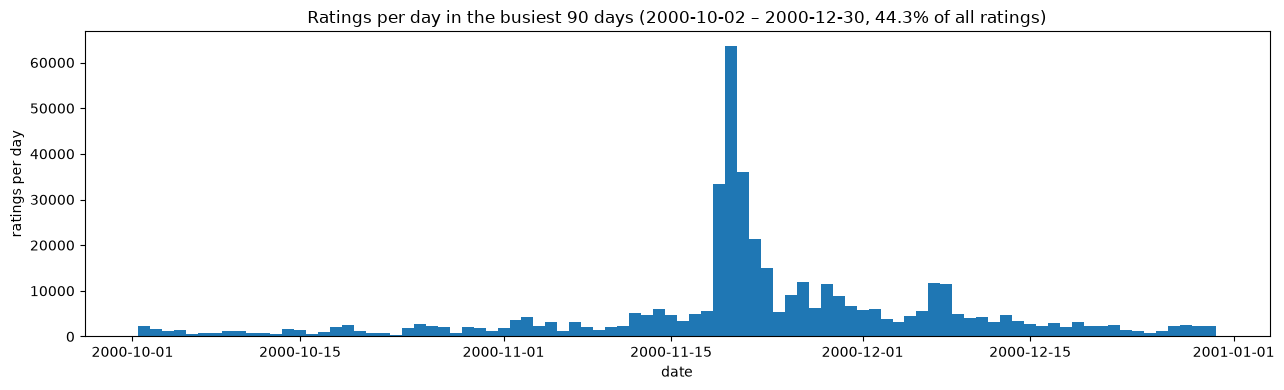

Busiest single days:


,ratings
date,
2000-11-20,63654
2000-11-21,36125
2000-11-19,33331
2000-11-22,21280
2000-08-03,20800


In [8]:
def plot_weekly(ax, cuts=None):
    ax.plot(weekly.index, weekly.values, drawstyle="steps-post")
    ax.set_yscale("log")
    ax.set_xlabel("date")
    ax.set_ylabel("ratings per week (log)")
    ax.set_title("Ratings per week over the whole span")
    for label, t, color in (cuts or []):
        ax.axvline(t, color=color, linestyle="--", label=label)
    if cuts:
        ax.legend()

fig, ax = plt.subplots(figsize=(13, 4))
plot_weekly(ax)
plt.tight_layout()
plt.show()

# Daily counts in the busiest 90-day period
daily = ratings.set_index("date").resample("D").size()
rolling = daily.rolling(90).sum()
busy_end = rolling.idxmax()
busy = daily.loc[busy_end - pd.Timedelta(days=89): busy_end]
fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(busy.index, busy.values, width=1.0)
ax.set_xlabel("date")
ax.set_ylabel("ratings per day")
ax.set_title(f"Ratings per day in the busiest 90 days ({busy.index[0].date()} – {busy.index[-1].date()}, "
             f"{100 * busy.sum() / n_ratings:.1f}% of all ratings)")
plt.tight_layout()
plt.show()
print("Busiest single days:")
display(daily.sort_values(ascending=False).head(5).to_frame("ratings"))

### Per-user burstiness

How long each user is active and how much of their history is entered in one burst. If most users rate
everything in one session, a global temporal cut separates *users* more than it separates a user's past
from their future — relevant for cold-start counts.

,value
% users with all ratings within 1 day,62.9305
% users with all ratings within 1 week,70.2483
% users with all ratings within 30 days,76.1921
median user activity span (hours),1.1301
median share of a user's ratings on their busiest day (%),100.0000
% users with >= 50% of ratings on one day,90.5629


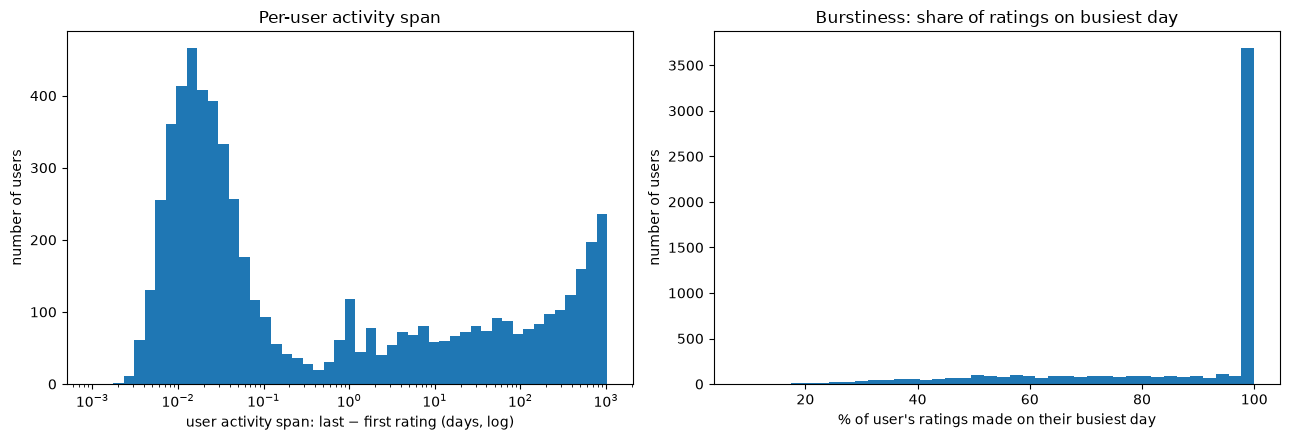

In [9]:
DAY = 24 * 3600
user_time = ratings.groupby("user_id")["ts"].agg(["min", "max"])
user_span_days = (user_time["max"] - user_time["min"]) / DAY

user_day = ratings.assign(day=ratings["date"].dt.floor("D")).groupby(["user_id", "day"]).size()
busiest_day_share = user_day.groupby("user_id").max() / per_user

burst = pd.Series({
    "% users with all ratings within 1 day": 100 * (user_span_days <= 1).mean(),
    "% users with all ratings within 1 week": 100 * (user_span_days <= 7).mean(),
    "% users with all ratings within 30 days": 100 * (user_span_days <= 30).mean(),
    "median user activity span (hours)": 24 * user_span_days.median(),
    "median share of a user's ratings on their busiest day (%)": 100 * busiest_day_share.median(),
    "% users with >= 50% of ratings on one day": 100 * (busiest_day_share >= 0.5).mean(),
})
display(burst.to_frame("value"))
for k, v in burst.items():
    record("4 time", k, round(v, 1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(user_span_days + 1e-3, bins=np.logspace(-3, np.log10(user_span_days.max() + 1), 50))
axes[0].set_xscale("log")
axes[0].set_xlabel("user activity span: last − first rating (days, log)")
axes[0].set_ylabel("number of users")
axes[0].set_title("Per-user activity span")
axes[1].hist(100 * busiest_day_share, bins=40)
axes[1].set_xlabel("% of user's ratings made on their busiest day")
axes[1].set_ylabel("number of users")
axes[1].set_title("Burstiness: share of ratings on busiest day")
plt.tight_layout()
plt.show()

## 5. The temporal split

Global temporal split from `config.yaml` (cut points at timestamp quantiles). Documents exactly where the
cut is, how big each part is, and who is evaluated: every user with at least one relevant (≥ 4) item in the evaluation split, including
cold-start users who have no train ratings (models that cannot handle them score 0 for those users).

train   800168 rows  2000-04-25 -> 2000-12-02
val     100020 rows  2000-12-02 -> 2000-12-29
test    100021 rows  2000-12-29 -> 2003-02-28

split config: {'val_frac': 0.1, 'test_frac': 0.1}
t_val  = 975768738 (2000-12-02 14:52:18)
t_test = 978133376 (2000-12-29 23:42:56)
rows add up: True


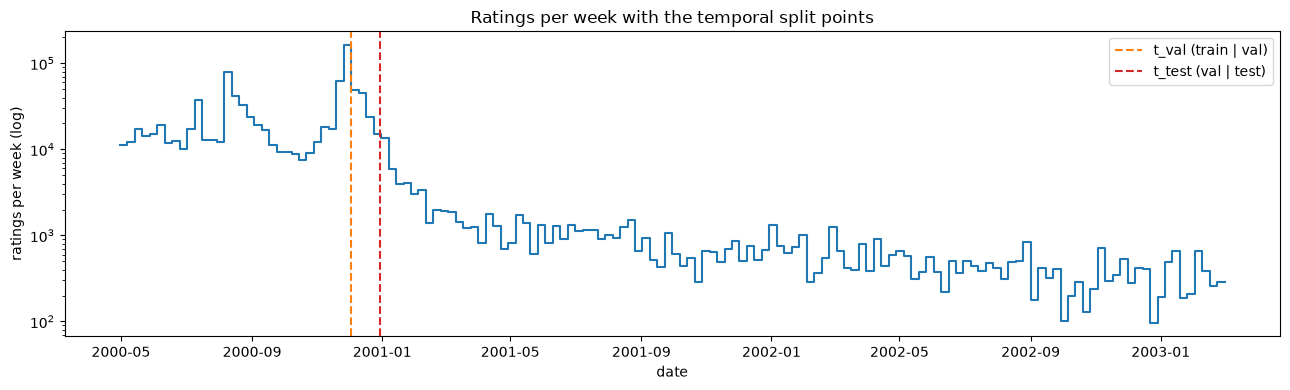

train covers 220 days, val 27 days, test 790 days


In [10]:
s = split(ds, cfg["split"])
print(s.summary())
t_val_date = pd.to_datetime(s.t_val, unit="s")
t_test_date = pd.to_datetime(s.t_test, unit="s")
print(f"\nsplit config: {cfg['split']}")
print(f"t_val  = {s.t_val} ({t_val_date})")
print(f"t_test = {s.t_test} ({t_test_date})")
print("rows add up:", s.train.n_ratings + s.val.n_ratings + s.test.n_ratings == n_ratings)
record("5 split", "t_val cut", str(t_val_date))
record("5 split", "t_test cut", str(t_test_date))
for name in ("train", "val", "test"):
    d = getattr(s, name)
    record("5 split", f"{name} rows / users / items", f"{d.n_ratings} / {d.n_users} / {d.n_items}")

fig, ax = plt.subplots(figsize=(13, 4))
plot_weekly(ax, cuts=[("t_val (train | val)", t_val_date, "tab:orange"),
                      ("t_test (val | test)", t_test_date, "tab:red")])
ax.set_title("Ratings per week with the temporal split points")
plt.tight_layout()
plt.show()
print(f"train covers {(t_val_date - t_min).days} days, val {(t_test_date - t_val_date).days} days, "
      f"test {(t_max - t_test_date).days} days")

In [11]:
def split_stats(name, eval_ratings, train_ratings, threshold=RELEVANCE_THRESHOLD):
    train_users = set(train_ratings["user_id"])
    train_items = set(train_ratings["item_id"])
    u = eval_ratings["user_id"]
    i = eval_ratings["item_id"]
    cold_user_rows = ~u.isin(train_users)
    cold_item_rows = ~i.isin(train_items)
    eval_users = set(u)
    pos = eval_ratings[eval_ratings["rating"] >= threshold]
    evaluated = set(pos["user_id"])
    return {
        "split": name,
        "rows": len(eval_ratings),
        "users": len(eval_users),
        "cold-start users (not in train)": len(eval_users - train_users),
        "% cold-start users": 100 * len(eval_users - train_users) / len(eval_users),
        "rows of cold-start users": int(cold_user_rows.sum()),
        "% rows of cold-start users": 100 * cold_user_rows.mean(),
        "items": i.nunique(),
        "items not in train": len(set(i) - train_items),
        "% rows with item not in train": 100 * cold_item_rows.mean(),
        f"users with >= 1 rating >= {threshold}": pos["user_id"].nunique(),
        "evaluated users (>= 1 relevant item)": len(evaluated),
        "evaluated users that are cold-start": len(evaluated - train_users),
        "% evaluated users that are cold-start": 100 * len(evaluated - train_users) / len(evaluated),
        "% of split users evaluated": 100 * len(evaluated) / len(eval_users),
        "relevant rows of evaluated users": int(pos["user_id"].isin(evaluated).sum()),
    }

split_table = pd.DataFrame([
    split_stats("val", s.val.ratings, s.train.ratings),
    split_stats("test", s.test.ratings, s.train.ratings),
    # test users seen in train OR val (if the model is retrained on train+val before testing)
    split_stats("test (train+val as history)", s.test.ratings,
                pd.concat([s.train.ratings, s.val.ratings])),
]).round(2).astype(object).set_index("split").T
display(split_table)
for col in split_table.columns:
    for metric in ["users", "% cold-start users", "% rows of cold-start users", "items not in train",
                   "evaluated users (>= 1 relevant item)", "% evaluated users that are cold-start"]:
        v = split_table.loc[metric, col]
        record("5 split", f"{col}: {metric}", round(float(v), 1) if isinstance(v, float) else v)

split,val,test,test (train+val as history)
rows,100020,100021,100021
users,1134,1209,1209
cold-start users (not in train),611,200,29
% cold-start users,53.8800,16.5400,2.4000
rows of cold-start users,76176,19326,4209
% rows of cold-start users,76.1600,19.3200,4.2100
items,3305,3407,3407
items not in train,16,33,28
% rows with item not in train,0.0200,0.1000,0.0900
users with >= 1 rating >= 4,1103,1188,1188


,val,test
count,"1,103.0000","1,188.0000"
mean,52.4098,45.8350
std,74.2213,62.2135
min,1.0000,1.0000
25%,8.0000,8.0000
50%,26.0000,24.0000
75%,68.0000,60.0000
90%,131.8000,109.9000
max,741.0000,588.0000


val: evaluated users with only 1 relevant item: 8.1%, with < 10 relevant items: 26.7%
test: evaluated users with only 1 relevant item: 5.0%, with < 10 relevant items: 29.6%


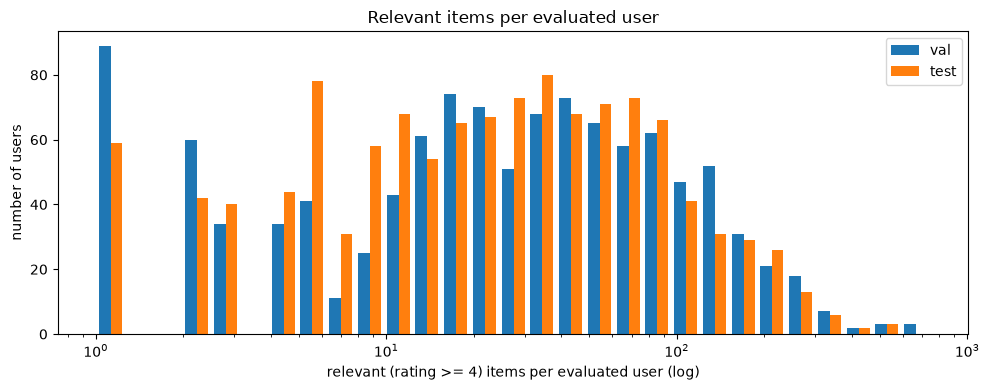

In [12]:
def relevant_per_user(eval_ratings, threshold=RELEVANCE_THRESHOLD):
    pos = eval_ratings[eval_ratings["rating"] >= threshold]
    return pos.groupby("user_id").size()

rel_val = relevant_per_user(s.val.ratings)
rel_test = relevant_per_user(s.test.ratings)
display(pd.DataFrame({"val": rel_val.describe(percentiles=[.25, .5, .75, .9]),
                      "test": rel_test.describe(percentiles=[.25, .5, .75, .9])}))
for name, rel in [("val", rel_val), ("test", rel_test)]:
    print(f"{name}: evaluated users with only 1 relevant item: {100 * (rel == 1).mean():.1f}%, "
          f"with < 10 relevant items: {100 * (rel < 10).mean():.1f}%")
    record("5 split", f"{name}: median relevant items per evaluated user", float(rel.median()))
    record("5 split", f"{name}: % evaluated users with < 10 relevant items", round(100 * (rel < 10).mean(), 1))

fig, ax = plt.subplots(figsize=(10, 4))
bins = np.logspace(0, np.log10(max(rel_val.max(), rel_test.max()) + 1), 30)
ax.hist([rel_val, rel_test], bins=bins, label=["val", "test"])
ax.set_xscale("log")
ax.set_xlabel(f"relevant (rating >= {RELEVANCE_THRESHOLD}) items per evaluated user (log)")
ax.set_ylabel("number of users")
ax.set_title("Relevant items per evaluated user")
ax.legend()
plt.tight_layout()
plt.show()

### Relevance definition: global threshold vs per-user threshold

The evaluation counts a held-out rating as relevant if it is ≥ 4 (`RELEVANCE_THRESHOLD`). A global threshold
ignores that users rate differently (a 4 from a generous rater means less than from a harsh one), so we compare
it with two per-user definitions: rating **above** / **at least** the user's mean rating. The mean is computed from **train** only,
so the definition of the "right answers" does not look at the data being evaluated. This also means the per-user rules are
only defined for users present in train (cold-start users have no train mean), which is one more practical
argument for a global threshold.

Because ratings are whole stars, a per-user mean threshold turns into an integer cut-off per user
(e.g. mean 3.7 → "> mean" means "≥ 4"). The tables show which cut-off users effectively get, how many
relevance labels differ from the global ≥ 4 rule, and how similar the per-user relevant sets are.
If the labels mostly agree, the simple global threshold is good enough for comparing models; whether the
*model ranking* changes under the per-user definition is checked separately in the tuning notebook.

,split,relevant if,% ratings relevant,evaluated users (>= 1 relevant),median relevant per evaluated user,% labels different from global,mean Jaccard of relevant sets vs global
0,val,>= 4 (global),53.0490,492,7.0000,0.0000,1.0000
1,val,> user's train mean,47.5550,478,6.0000,13.4460,0.8330
2,val,>= user's train mean,50.5030,478,6.0000,11.7390,0.8390
3,test,>= 4 (global),54.0800,993,23.0000,0.0000,1.0000
4,test,> user's train mean,46.2060,974,19.0000,12.8710,0.8190
5,test,>= user's train mean,47.5790,977,19.0000,12.1440,0.8330


,users,% users
'> mean' means rating >=,,
2,1,0.1000
3,70,6.1000
4,758,66.3000
5,314,27.5000


val mean - train mean per user: median -0.04, |difference| > 0.5 stars for 34% of users


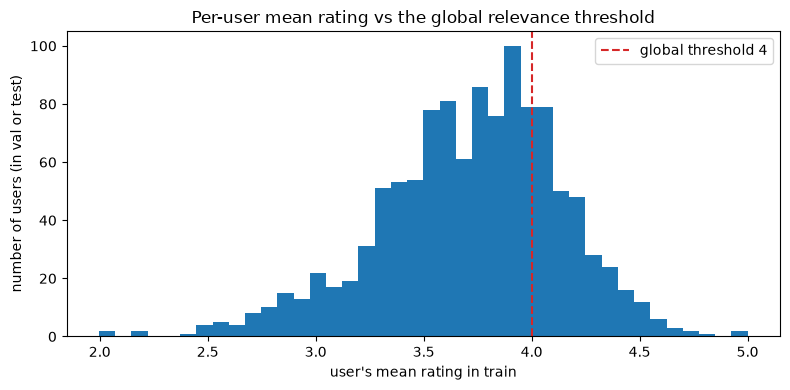

In [13]:
train_user_mean = s.train.ratings.groupby("user_id")["rating"].mean()

def relevance_rules(eval_ratings):
    """Boolean 'relevant' labels for each eval rating under each definition (users present in train only)."""
    r = eval_ratings[eval_ratings["user_id"].isin(train_user_mean.index)]
    mean = r["user_id"].map(train_user_mean)
    rules = {
        f">= {RELEVANCE_THRESHOLD} (global)": r["rating"] >= RELEVANCE_THRESHOLD,
        "> user's train mean": r["rating"] > mean,
        ">= user's train mean": r["rating"] >= mean,
    }
    return r, rules

def mean_jaccard(r, a, b):
    """Average over users of |A ∩ B| / |A ∪ B| of the relevant sets under two rules (users with any relevant item)."""
    sets_a = r[a].groupby("user_id")["item_id"].apply(set)
    sets_b = r[b].groupby("user_id")["item_id"].apply(set)
    users = sets_a.index.union(sets_b.index)
    scores = [len(sets_a.get(u, set()) & sets_b.get(u, set())) / len(sets_a.get(u, set()) | sets_b.get(u, set()))
              for u in users]
    return float(np.mean(scores))

rows = []
for split_name, eval_ratings in [("val", s.val.ratings), ("test", s.test.ratings)]:
    r, rules = relevance_rules(eval_ratings)
    base = rules[f">= {RELEVANCE_THRESHOLD} (global)"]
    for rule_name, relevant in rules.items():
        per_user = relevant.groupby(r["user_id"]).sum()
        rows.append({
            "split": split_name,
            "relevant if": rule_name,
            "% ratings relevant": 100 * relevant.mean(),
            "evaluated users (>= 1 relevant)": int((per_user > 0).sum()),
            "median relevant per evaluated user": float(per_user[per_user > 0].median()),
            "% labels different from global": 100 * (relevant != base).mean(),
            "mean Jaccard of relevant sets vs global": mean_jaccard(r, relevant, base),
        })
relevance_table = pd.DataFrame(rows)
display(relevance_table.round(3))

# Which integer cut-off does "> train mean" correspond to for each evaluated user?
users_in_eval = pd.Index(pd.concat([s.val.ratings, s.test.ratings])["user_id"].unique()).intersection(train_user_mean.index)
effective_cutoff = (np.floor(train_user_mean[users_in_eval]) + 1).clip(upper=5).astype(int)
cutoff_table = effective_cutoff.value_counts().sort_index().to_frame("users")
cutoff_table["% users"] = 100 * cutoff_table["users"] / cutoff_table["users"].sum()
cutoff_table.index.name = "'> mean' means rating >="
display(cutoff_table.round(1))

# Do users rate differently in the evaluation period than in train? (drift makes a train-based mean less reliable)
val_known = s.val.ratings[s.val.ratings["user_id"].isin(train_user_mean.index)]
drift = val_known.groupby("user_id")["rating"].mean() - train_user_mean
drift = drift.dropna()
print(f"val mean - train mean per user: median {drift.median():+.2f}, "
      f"|difference| > 0.5 stars for {100 * (drift.abs() > 0.5).mean():.0f}% of users")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(train_user_mean[users_in_eval], bins=40)
ax.axvline(RELEVANCE_THRESHOLD, color="tab:red", linestyle="--", label=f"global threshold {RELEVANCE_THRESHOLD}")
ax.set_xlabel("user's mean rating in train")
ax.set_ylabel("number of users (in val or test)")
ax.set_title("Per-user mean rating vs the global relevance threshold")
ax.legend()
plt.tight_layout()
plt.show()

for _, row in relevance_table.iterrows():
    if row["relevant if"] != f">= {RELEVANCE_THRESHOLD} (global)":
        record("5 split", f"{row['split']}: % labels changed, '{row['relevant if']}' vs global",
               round(row["% labels different from global"], 1))
_ = record("5 split", "% users for whom '> train mean' = '>= 4'",
       round(cutoff_table.loc[4, "% users"], 1) if 4 in cutoff_table.index else 0.0)

## 6. Filtering analysis (analysis only — pipeline unchanged)

Assignment: *"If you filter out low-activity users or items, state the threshold and how many rows it removed."*
Thresholds are applied to **train** counts (filtering must not look at val/test). Each threshold is applied
on its own (single pass, not iterated to a fixed point). "Affected val/test rows" are rows whose item
(or user) exists in train but would be removed by the filter, so a model trained on filtered data could not score it.
Items/users absent from train altogether are counted separately in Section 5.

In [14]:
train_r = s.train.ratings
train_item_counts = train_r.groupby("item_id").size()
train_user_counts = train_r.groupby("user_id").size()

def filter_effect(counts, column, threshold):
    kept = set(counts[counts >= threshold].index)
    removed_ids = len(counts) - len(kept)
    train_removed = (~train_r[column].isin(kept)).sum()
    return {
        "threshold (min train ratings)": threshold,
        f"{column}s removed": removed_ids,
        f"% {column}s removed": 100 * removed_ids / len(counts),
        "train rows removed": int(train_removed),
        "% train rows removed": 100 * train_removed / len(train_r),
        # val/test rows whose id is *in train* but would be filtered away
        "val rows affected": int((s.val.ratings[column].isin(counts.index)
                                  & ~s.val.ratings[column].isin(kept)).sum()),
        "% val rows affected": 100 * (s.val.ratings[column].isin(counts.index)
                                      & ~s.val.ratings[column].isin(kept)).mean(),
        "% test rows affected": 100 * (s.test.ratings[column].isin(counts.index)
                                       & ~s.test.ratings[column].isin(kept)).mean(),
    }

item_filter = pd.DataFrame([filter_effect(train_item_counts, "item_id", t) for t in [1, 5, 10, 20, 50]])
user_filter = pd.DataFrame([filter_effect(train_user_counts, "user_id", t) for t in [1, 5, 10, 20]])
print("Item threshold (min ratings per item in train):")
display(item_filter)
print("User threshold (min ratings per user in train):")
display(user_filter)
for _, r in item_filter.iterrows():
    record("6 filtering", f"item min {r['threshold (min train ratings)']}: train rows removed / % val rows affected",
           f"{int(r['train rows removed'])} / {r['% val rows affected']:.2f}%")
for _, r in user_filter.iterrows():
    record("6 filtering", f"user min {r['threshold (min train ratings)']}: train rows removed / % val rows affected",
           f"{int(r['train rows removed'])} / {r['% val rows affected']:.2f}%")

Item threshold (min ratings per item in train):


,threshold (min train ratings),item_ids removed,% item_ids removed,train rows removed,% train rows removed,val rows affected,% val rows affected,% test rows affected
0,1,0,0.0000,0,0.0000,0,0.0000,0.0000
1,5,315,8.6019,633,0.0791,105,0.1050,0.2899
2,10,507,13.8449,1948,0.2434,327,0.3269,0.6709
3,20,765,20.8902,5649,0.7060,875,0.8748,1.6187
4,50,1339,36.5647,24744,3.0924,3453,3.4523,5.2489


User threshold (min ratings per user in train):


,threshold (min train ratings),user_ids removed,% user_ids removed,train rows removed,% train rows removed,val rows affected,% val rows affected,% test rows affected
0,1,0,0.0000,0,0.0000,0,0.0000,0.0000
1,5,8,0.1481,26,0.0032,209,0.2090,0.3969
2,10,57,1.0556,349,0.0436,810,0.8098,4.9380
3,20,99,1.8333,964,0.1205,2725,2.7245,8.1373


## 7. Side information overview

Movies are multi-label (a movie can have several genres). Useful later for content-based models and
for describing what the long tail consists of

18 genres; mean genres per movie: 1.65; movies with missing year: 0


,movies,ratings,% of ratings
genres,,,
Drama,1603,354529,35.4455
Comedy,1200,356580,35.6505
Action,503,257457,25.7403
Thriller,492,189680,18.9640
Romance,471,147523,14.7492
Horror,343,76386,7.6370
Adventure,283,133953,13.3925
Sci-Fi,276,157294,15.7261
Children's,251,72186,7.2171


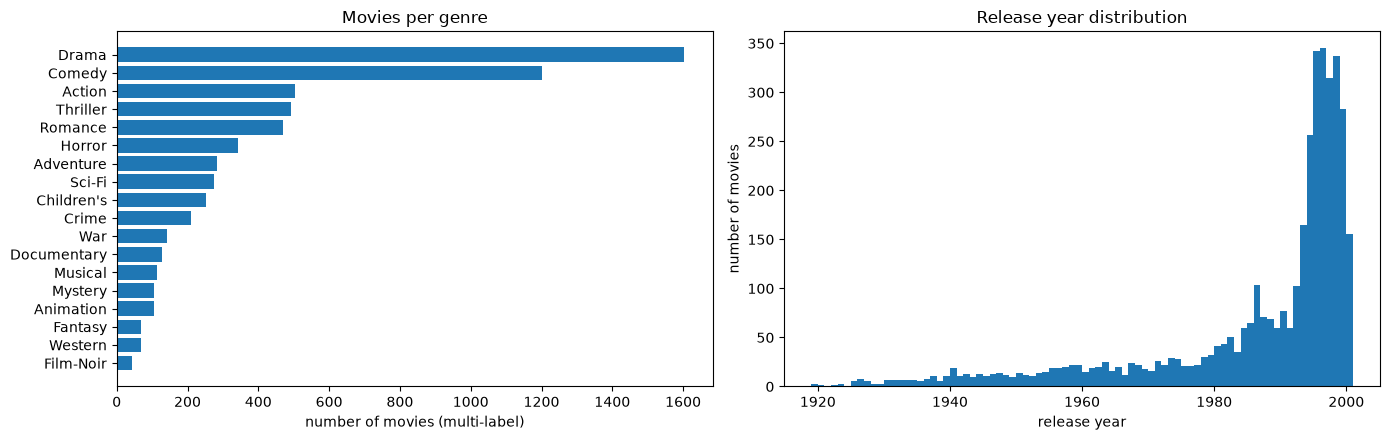

In [15]:
genre_movies = movies.explode("genres")["genres"].value_counts()
rated_genres = ratings[["item_id"]].merge(movies[["item_id", "genres"]], on="item_id").explode("genres")
genre_ratings = rated_genres["genres"].value_counts()
genre_table = pd.DataFrame({"movies": genre_movies, "ratings": genre_ratings}).sort_values("movies", ascending=False)
genre_table["% of ratings"] = 100 * genre_table["ratings"] / n_ratings
print(f"{genre_table.shape[0]} genres; mean genres per movie: {movies['genres'].str.len().mean():.2f}; "
      f"movies with missing year: {movies['year'].isna().sum()}")
display(genre_table)
record("7 side info", "number of genres", genre_table.shape[0])
record("7 side info", "mean genres per movie", round(movies["genres"].str.len().mean(), 2))
record("7 side info", "release years", f"{movies['year'].min()} – {movies['year'].max()}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].barh(genre_table.index[::-1], genre_table["movies"][::-1])
axes[0].set_xlabel("number of movies (multi-label)")
axes[0].set_title("Movies per genre")
years = movies["year"].dropna().astype(int)
axes[1].hist(years, bins=range(years.min(), years.max() + 2))
axes[1].set_xlabel("release year")
axes[1].set_ylabel("number of movies")
axes[1].set_title("Release year distribution")
plt.tight_layout()
plt.show()

## 8. Summary table

Key numbers from all sections in one place, for copying into the report.

In [16]:
summary = pd.DataFrame(SUMMARY, columns=["section", "metric", "value"])
summary["value"] = summary["value"].astype(str)
with pd.option_context("display.max_rows", 200, "display.max_colwidth", 80):
    display(summary)

,section,metric,value
0,1 basic,users,6040
1,1 basic,items rated,3706
2,1 basic,movies in movies.dat,3883
3,1 basic,movies never rated,177
4,1 basic,ratings,1000209
5,1 basic,density,0.0447
6,1 basic,min / median / max ratings per user,20 / 96 / 2314
7,1 basic,min / median / max ratings per item,1 / 124 / 3428
8,2 long tail,% of ratings on top 1% items,8.7
9,2 long tail,% of ratings on top 5% items,28.3
